## **Exploratory Data Analysis on Student Dataset**

#### **Dataset Schema**

> **University**(Student_ID, Full_Name, Application_Date, Date_of_Birth, Age, Department, Country, Email, Fee_Paid, GPA, Attendance_Percentage, Is_Active,Enrollment_Status)

We have three distinct types of features to analyze:

- **Numerical**: `Age`, `Fee_Paid`, `GPA`, `Attendance_Percentage`

- **Categorical**: `Department`, `Country`, `Is_Active`, `Enrollment_Status`

- **Temporal**: `Application_Date`, `Date_of_Birth`

- **Identifiers/Text**: `Student_ID`, `Full_Name`, `Email`.



#### **Let's Ingest the Dataset**

In [24]:
import pandas as pd
import numpy as np
import os 
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
# Finished importing required modules.

# The Base Directory
BASE_DIR: str = '../../Data_Cleaning_and_Preprocessing/cleaned_data_sets/Production/'
# File path.
file_path: str = f'{BASE_DIR}/Production_University_Data_v1.parquet'

def load_production_data(file_path: Path | str) -> pd.DataFrame:
    """Safely loads a Parquet file with built-in validation."""

    # 1. Convert string to Path object if necessary
    path_obj = Path(file_path)

    # 2. Defensinve Check: Does the file actually exist?
    if not path_obj.exists():
        raise FileNotFoundError(f'[CRITICAL ERROR] The data file is missing: {path_obj.resolve()}')

    try:
        # 3. The Actual Load
        print(f'Loading data from {path_obj.name}...')
        df = pd.read_parquet(path_obj)

        print(f'[SUCCESS] Successfully loaded {len(df)} rows.')
        return df
    except Exception as e:
        print(f'[CRITICAL ERROR] Failed to read the Parquet file. It may be corrupted. Details: {e}')
        raise # re-raise the error because the pipeline cannot continue without data

uni_df: pd.DataFrame = load_production_data(file_path=file_path)

Loading data from Production_University_Data_v1.parquet...
[SUCCESS] Successfully loaded 915 rows.


In [5]:
uni_df.head()

,STUDENT_ID,FULL_NAME,APPLICATION_DATE,DATE_OF_BIRTH,AGE,DEPARTMENT,COUNTRY,EMAIL,FEE_PAID,GPA,ATTENDANCE_PERCENTAGE,IS_ACTIVE,LAB_SENSOR_RPM,ENROLLMENT_STATUS
0,STU00114,Farhan Farooqi,2022-04-16,1980-04-25,44,data science,India,farhan.farooqi114@gmail.com,3579.9300,2.91,70.3,False,4289.05,unknown
1,STU00793,Riya Rana,2021-07-08,2002-12-13,21,finance,India,riya.rana793@yahoo.com,0.0000,2.88,41.4,True,1430.70,Graduated
2,STU00741,Karan Kapoor,2021-06-06,1989-06-21,34,electrical engineering,Pakistan,karan.kapoor741@outlook.com,4843.1500,2.34,90.1,True,1093.00,Enrolled
3,STU00432,Ava Siddiqui,2024-04-03,2004-03-31,20,data science,USA,ava.siddiqui432@yahoo.com,2488.4800,1.86,84.9,False,4289.05,Withdrawn
4,STU00243,Anjali Young,2024-03-16,1989-09-22,34,business administration,UAE,anjali.young243@outlook.com,0.4503,3.53,64.0,False,2536.60,Withdrawn


**A Corruption , found it the dataset, I guess the cleaning process didn't go much well....**

The Age and Date_of_Birth doesn't match properly let's fix it first.....

- **HOW**: let's create a new column containing the correct date of birth and age combination. Flag the wrong one , and fix them.

**NOTE**: There's Catch on the fixing via this approach...for those whose birthday isn't come yet in 2026, they might be calculated as few months older, however we'll fix that later.


In [18]:
curr_year: int = 2026 # current year

# The new Correct Age column.
uni_df['CORRECT_AGE'] = curr_year - uni_df['DATE_OF_BIRTH'].dt.year

# let's flag the curropted age columns.
flag_mask = uni_df['AGE'] != uni_df['CORRECT_AGE']

# uni_df[flag_mask].shape # 866 rows are corrupted....massive.

uni_df.loc[flag_mask,'AGE'] = uni_df['CORRECT_AGE']

uni_df.head()

,STUDENT_ID,FULL_NAME,APPLICATION_DATE,DATE_OF_BIRTH,AGE,DEPARTMENT,COUNTRY,EMAIL,FEE_PAID,GPA,ATTENDANCE_PERCENTAGE,IS_ACTIVE,ENROLLMENT_STATUS,CORRECT_AGE
0,STU00114,Farhan Farooqi,2022-04-16,1980-04-25,46,data science,India,farhan.farooqi114@gmail.com,3579.9300,2.91,70.3,False,unknown,46
1,STU00793,Riya Rana,2021-07-08,2002-12-13,24,finance,India,riya.rana793@yahoo.com,0.0000,2.88,41.4,True,Graduated,24
2,STU00741,Karan Kapoor,2021-06-06,1989-06-21,37,electrical engineering,Pakistan,karan.kapoor741@outlook.com,4843.1500,2.34,90.1,True,Enrolled,37
3,STU00432,Ava Siddiqui,2024-04-03,2004-03-31,22,data science,USA,ava.siddiqui432@yahoo.com,2488.4800,1.86,84.9,False,Withdrawn,22
4,STU00243,Anjali Young,2024-03-16,1989-09-22,37,business administration,UAE,anjali.young243@outlook.com,0.4503,3.53,64.0,False,Withdrawn,37


In [21]:
# let's drop the exatra Correct Age column.
# uni_df = uni_df.drop(columns='CORRECT_AGE')

# the lab sensor column is also useless in this particular dataset.
# uni_df = uni_df.drop(columns='LAB_SENSOR_RPM')

**Since we fix a kind of Data Inconsistency**

Let's move on to our Univariate Analysis....

#### **1. Univariate Analysis**

Before comparing variables, we must first analze them into isolation, this is basically for getting hold with the shape of dataset.

- **Numerical Data**: We find out the central tendency (mean, median) and dispersion (standard deviation, variance) we look for outliers and skewness via ploting Histograms and boxplot.

- **Categorical Data**: we analyze frequency distribution. let's take an example we'll find out most of our students are from which country... we will use Bar chart for it.

In [23]:
# For Numerical values, pandas does have a built-in method, to get a quick
# answer for central tendency and dispertions.

numerical_cols: list = ['AGE', 'GPA', 'ATTENDANCE_PERCENTAGE', 'FEE_PAID']

uni_df[numerical_cols].describe()

,AGE,GPA,ATTENDANCE_PERCENTAGE,FEE_PAID
count,915.000000,915.000000,915.000000,915.000000
mean,33.978142,2.822667,70.154863,1694.393750
std,8.250825,0.737827,17.911601,1729.065141
min,19.000000,1.500000,0.000000,0.000000
25%,27.000000,2.155000,56.150000,0.221400
50%,34.000000,2.880000,70.300000,1289.760000
75%,41.000000,3.470000,85.050000,3242.955000
max,48.000000,4.000000,100.000000,4989.660000


#### **Let's plot the chart**

we will use all of them, `Pandas` built-in plot , `matplotlib`, and `seaborn`.

Let's see the difference first.

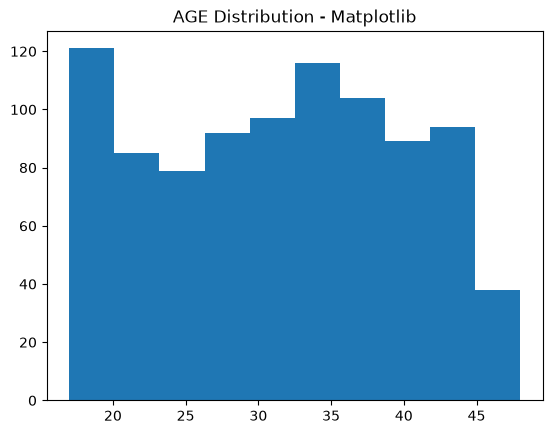

In [26]:
# Matplotlib.

plt.hist(uni_df['AGE'])
plt.title('AGE Distribution - Matplotlib')
plt.show()

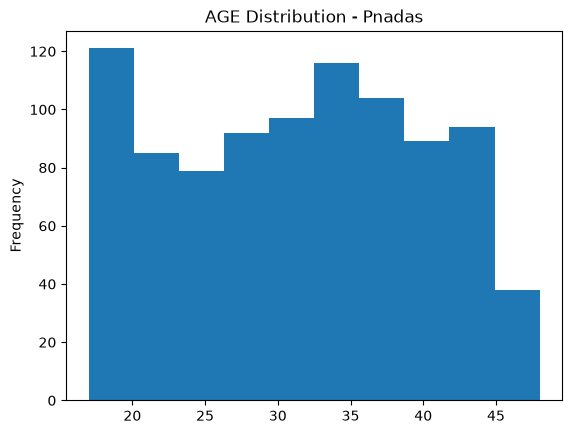

In [27]:
# Pandas
uni_df['AGE'].plot(kind='hist', title='AGE Distribution - Pnadas')
plt.show()

In [ ]:
# Seaborn
sns.histplot(data=uni_df, x='AGE')
plt.title('AGE Distribution - Seaborn')
# plt.show()

NameError: name 'sns' is not defined